# The Epydemix Command-Line Interface
[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/epistorm/epydemix/blob/main/tutorials/13_Command_Line_Interface.ipynb)

If you are running this tutorial on Google Colab, you can install the needed packages by running the following cell:

In [1]:
import sys, os, subprocess
if "google.colab" in sys.modules or os.getenv("COLAB_RELEASE_TAG"):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "epydemix[agent]", "matplotlib"])

Besides its Python API, **epydemix** ships an `epydemix` command-line tool. It is the interface of the epydemix **agent framework**: it is designed so that an LLM agent (or any automation pipeline) can discover models, configure them, run them, and ask questions about the results without reading source code or keeping Python objects in memory. The same properties make it convenient from a plain terminal too:

- **Discoverable**: models, parameters, and disease presets can be listed from the CLI.
- **Declarative**: a simulation is one YAML file, checked by a validator before anything runs.
- **Stateless**: every command reads files and writes files, nothing lives in memory between calls.
- **Structured**: results are saved as self-describing *bundles* (Parquet files plus a JSON manifest), and every command prints JSON.

In this tutorial we follow one question from start to finish:

> *How does the timing of a six-week reduction in transmission change a COVID-19-like epidemic in Italy?*

Along the way we cover:

1. **Discovery**: which models, parameters, presets, and populations are available
2. **Configs and validation**: writing a YAML config and catching mistakes before running
3. **Running and inspecting**: simulation bundles and targeted queries on them
4. **Scenarios**: config inheritance and side-by-side comparison
5. **Calibration and projection**: fitting a model to data and asking "what if?"
6. **Back to Python**: reading bundles with pandas and plotting them
7. **Agents**: how an LLM agent uses all of the above

In a notebook, shell commands are prefixed with `!`. In a terminal, type the same commands without it. We work inside a scratch folder so that configs and results don't mix with the tutorial files:

In [2]:
os.makedirs("cli_tutorial", exist_ok=True)
%cd -q cli_tutorial

## 1. Discovery

The CLI can describe itself. `epydemix models` lists the predefined model backbones:

In [3]:
!epydemix models

{
  "models": [
    "SIR",
    "SEIR",
    "SIS",
    "SEIAR"
  ]
}


`epydemix schema` describes a model's parameters: their meaning, units, valid range, and default. By default it prints a JSON Schema (convenient for programs); `--format describe` gives a human-readable version:

In [4]:
!epydemix schema SEIR --format describe

This model has 3 parameters:

- transmission_rate: Rate at which susceptible individuals become exposed through contact with infected individuals. Controls the force of infection. Higher values produce faster epidemic growth. Units: 1/days. Valid range: [0, 10]. Default: 0.3.
- incubation_rate: Rate at which exposed individuals become infectious. The inverse (1/incubation_rate) gives the mean latent (incubation) period in days. Units: 1/days. Valid range: [0, 10]. Default: 0.2.
- recovery_rate: Rate at which infected individuals recover and become immune. The inverse (1/recovery_rate) gives the mean infectious period in days. Units: 1/days. Valid range: [0, 10]. Default: 0.1.


Modular extensions (waning immunity, vaccination, deaths, hospitalization) can be added with flags, e.g. `epydemix schema SEIR --waning-immunity --outcome deaths`, and their parameters show up in the schema.

`epydemix defaults` gives literature-based parameter sets for a few diseases:

In [5]:
!epydemix defaults covid19

{
  "name": "COVID-19 (Omicron-like)",
  "model_type": "SEIR",
  "source": "Literature consensus values for Omicron-era COVID-19",
  "description": "Default parameters for a basic SEIR model of COVID-19, calibrated to Omicron-era epidemiology. Transmission rate reflects a moderate scenario without major interventions. Incubation ~3 days, infectious period ~7 days.\n",
  "parameters": {
    "transmission_rate": {
      "value": 0.4,
      "range": [
        0.2,
        0.8
      ],
      "units": "1/days",
      "description": "Effective transmission rate per contact per day"
    },
    "incubation_rate": {
      "value": 0.33,
      "range": [
        0.25,
        0.5
      ],
      "units": "1/days",
      "description": "Rate of progression from exposed to infectious (1/mean_incubation_period, ~3 days)"
    },
    "recovery_rate": {
      "value": 0.14,
      "range": [
        0.1,
        0.2
      ],
      "units": "1/days",
      "description": "Rate of recovery from infection 

Finally, `epydemix populations` lists the 400+ populations (with age structure and contact matrices) available from [epydemix-data](https://github.com/epistorm/epydemix-data/). The list is long, so we filter it:

In [6]:
!epydemix populations | grep Italy

    "Italy",


### Choosing a transmission rate for a real population

The preset `transmission_rate` of 0.4 assumes homogeneous mixing. With a real population, infections spread through the age-structured contact matrices, and the basic reproduction number becomes

$$R_0 = \frac{\beta \, \rho(C)}{\gamma}$$

where $\rho(C)$ is the spectral radius (largest eigenvalue) of the overall contact matrix. With Italy's contact matrices, the preset value would give an $R_0$ far above any realistic value. We instead pick $\beta$ to obtain $R_0 = 2.5$, keeping the preset incubation and recovery rates:

In [7]:
import numpy as np
from epydemix.population import load_epydemix_population

italy = load_epydemix_population("Italy")
C = sum(italy.contact_matrices[layer] for layer in ["home", "work", "school", "community"])
rho = np.max(np.abs(np.linalg.eigvals(C)))

recovery_rate = 0.14
transmission_rate = 2.5 * recovery_rate / rho
print(f"spectral radius = {rho:.2f}, transmission_rate = {transmission_rate:.4f}")

spectral radius = 13.90, transmission_rate = 0.0252


## 2. Writing and validating a config

A simulation is fully described by one YAML file. Here is our baseline: an SEIR model on Italy's population over the 2024-25 season, with no intervention. `n_simulations` sets the number of stochastic runs and `seed` makes them reproducible (if omitted, a seed is drawn and recorded for you). Note that predefined models use full compartment names (`Susceptible`, `Exposed`, ...) in `initial_conditions`.

In [8]:
%%writefile baseline.yaml
model:
  type: SEIR

parameters:
  transmission_rate: 0.025   # R0 = 2.5 on Italy's contact matrices
  incubation_rate: 0.33      # ~3 days latent period
  recovery_rate: 0.14        # ~7 days infectious period

population:
  name: Italy
  contact_layers: [home, work, school, community]

simulation:
  start_date: "2024-10-01"
  end_date: "2025-03-31"
  n_simulations: 50
  seed: 42

initial_conditions:
  Susceptible: 0.99999
  Exposed: 0.000005
  Infected: 0.000005
  Recovered: 0.0

Writing baseline.yaml


`epydemix validate` checks a config without running it. Beyond the structure of the file, it checks parameter names and ranges against the model, dates, and compartment names:

In [9]:
!epydemix validate baseline.yaml

{
  "valid": true,
  "errors": [],
  "warnings": []
}


To see what the validator catches, here is the same config with three common mistakes: a misspelled parameter, a rate entered as a duration (14 days instead of 1/14 per day), and a short compartment name:

In [10]:
%%writefile broken.yaml
model:
  type: SEIR

parameters:
  transmision_rate: 0.025
  incubation_rate: 0.33
  recovery_rate: 14

population:
  name: Italy
  contact_layers: [home, work, school, community]

simulation:
  start_date: "2024-10-01"
  end_date: "2025-03-31"

initial_conditions:
  S: 0.99999
  Exposed: 0.000005
  Infected: 0.000005
  Recovered: 0.0

Writing broken.yaml


In [11]:
!epydemix validate broken.yaml

{
  "valid": false,
  "errors": [
    "parameters: 'transmision_rate' is not a parameter of this model (did you mean 'transmission_rate'?). Parameters: transmission_rate, incubation_rate, recovery_rate",
    "parameters.recovery_rate has value 14, above the maximum of 10 (1/days) for 'recovery_rate'",
    "initial_conditions: 'S' is not a compartment of this model, so its value would be ignored (predefined models use full compartment names, e.g. 'Susceptible'). Compartments: Susceptible, Exposed, Infected, Recovered"
  ],
  "warnings": [
    "No value given for transmission_rate = 0.3; using the model default"
  ]
}


Each error says what is wrong and how to fix it, and the command exits with a non-zero status. Without these checks, the misspelled parameter and the unknown compartment would be silently ignored, and the simulation would run with values you never chose. `epydemix run` performs the same checks and refuses to run an invalid config.

## 3. Running and inspecting

`epydemix run` runs the simulations and saves them as a **bundle**, a folder with a `.epx` extension. It also prints the bundle's manifest; we discard it here since we look at the bundle directly:

In [12]:
!epydemix run baseline.yaml -o baseline.epx > /dev/null
print(*sorted(os.listdir("baseline.epx")), sep="\n")

Bundle saved to: baseline.epx


compartments.parquet
config.yaml
figures
manifest.json
parameters.parquet
transitions.parquet


The bundle contains:

- `compartments.parquet` and `transitions.parquet`: one row per simulation and date, with a column per compartment (or transition) and age group, plus `_total` columns summed over age groups
- `manifest.json`: what the bundle contains, the parameters used, the column schema of every file, and provenance (which command and config produced it)
- `config.yaml`: the config that produced the bundle, including the seed, so `epydemix run baseline.epx/config.yaml -o replay.epx` reproduces the exact same trajectories
- `parameters.parquet`: the parameters of each simulation (only filled for calibrations)
- `figures/`: an empty folder for plots of these results (see section 6)

Rather than loading millions of values to answer a simple question, `epydemix inspect` returns compact answers. When does the epidemic peak, and how high?

In [13]:
!epydemix inspect baseline.epx peak -v Infected_total --round 0

{
  "Infected_total": {
    "peak_date": {
      "0.05": "2025-01-18",
      "0.50": "2025-01-19",
      "0.95": "2025-01-21"
    },
    "peak_value": {
      "0.05": 8255447.0,
      "0.50": 8261596.0,
      "0.95": 8270369.0
    }
  }
}


Quantiles over time, here weekly in January and as CSV rather than JSON:

In [14]:
!epydemix inspect baseline.epx quantiles -v Infected_total -q 0.05,0.5,0.95 --start 2025-01-01 --end 2025-01-31 --resample W --format csv --round 0

date,Infected_total_0.05,Infected_total_0.5,Infected_total_0.95
2025-01-05,4941446.0,5328746.0,5782543.05
2025-01-12,7051367.75,7351952.5,7663052.9
2025-01-19,8213881.2,8253452.0,8268198.7
2025-01-26,7355065.45,7623916.0,7832117.8
2025-02-02,6166455.55,6521428.0,6822015.25



Other queries include `summary` (peak, final value, and mean of a variable) and `manifest`. Run `epydemix inspect --help` for the full list.

## 4. Comparing scenarios

We now compare three intervention timings. In each, `transmission_rate` drops by 40% (from 0.025 to 0.015) for six weeks, starting in mid-November, mid-December, or mid-January.

Rather than copying the whole config three times, each scenario **inherits** from the baseline with `base:` and only states what changes. Inherited settings are merged with the overlay: dictionaries are merged key by key, and anything else (such as a list) replaces the inherited value.

In [15]:
scenarios = {
    "early": ("2024-11-15", "2024-12-27"),
    "mid": ("2024-12-15", "2025-01-26"),
    "late": ("2025-01-15", "2025-02-26"),
}
for name, (start, end) in scenarios.items():
    with open(f"{name}.yaml", "w") as f:
        f.write(f"""base: baseline.yaml
overrides:
  - parameter: transmission_rate
    start_date: "{start}"
    end_date: "{end}"
    value: 0.015
""")

!cat early.yaml

base: baseline.yaml
overrides:
  - parameter: transmission_rate
    start_date: "2024-11-15"
    end_date: "2024-12-27"
    value: 0.015


Each overlay is validated and run like any other config:

In [16]:
!for s in early mid late; do epydemix validate $s.yaml > /dev/null && epydemix run $s.yaml -o $s.epx > /dev/null; done

Bundle saved to: early.epx


Bundle saved to: mid.epx


Bundle saved to: late.epx


`epydemix compare` computes the same metrics on several bundles at once, and with `-b` reports the differences from a baseline. Scenarios are named after their bundle:

In [17]:
!epydemix compare baseline.epx early.epx mid.epx late.epx -m attack_rate,peak,peak_date -b baseline --round 1

{
  "baseline": {
    "attack_rate": {
      "median": 80.7,
      "ci90": [
        80.7,
        80.8
      ],
      "units": "percent"
    },
    "peak": {
      "median": 8261595.5,
      "ci90": [
        8255446.8,
        8270369.3
      ],
      "variable": "Infected_total"
    },
    "peak_date": {
      "median": "2025-01-19",
      "ci90": [
        "2025-01-18",
        "2025-01-21"
      ],
      "variable": "Infected_total"
    }
  },
  "early": {
    "attack_rate": {
      "median": 79.8,
      "ci90": [
        79.8,
        79.9
      ],
      "units": "percent"
    },
    "peak": {
      "median": 8092750.0,
      "ci90": [
        8075492.5,
        8110912.0
      ],
      "variable": "Infected_total"
    },
    "peak_date": {
      "median": "2025-02-14",
      "ci90": [
        "2025-02-13",
        "2025-02-15"
      ],
      "variable": "Infected_total"
    }
  },
  "mid": {
    "attack_rate": {
      "median": 74.5,
      "ci90": [
        74.1,
        75.0
  

Timing matters a lot, and each scenario helps in a different way:

- **Early**: the measure ends before the epidemic takes off, so it mostly delays it. The peak comes about four weeks later, but its size and the final attack rate are barely changed.
- **Mid**: the measure covers the growth phase and the peak, and gives the lowest peak, about a third lower than the baseline. This is the scenario to choose if the goal is to protect hospital capacity.
- **Late**: the measure starts at the peak, which it barely lowers, but it cuts transmission while many people are infectious and reduces the final attack rate the most, by about 12 percentage points.

## 5. Calibration and projection

So far we chose the parameters ourselves. The CLI can also estimate them from data with Approximate Bayesian Computation (ABC), as in [Tutorial 4](./04_Model_Calibration_part1.ipynb), which we follow here with the same synthetic incidence data and model. First, we download the data:

In [18]:
import pandas as pd

url = "https://raw.githubusercontent.com/epistorm/epydemix/refs/heads/main/tutorials/data/incidence_data.csv"
pd.read_csv(url).to_csv("incidence_data.csv", index=False)
!head -n 4 incidence_data.csv

data,date
58329,2024-01-01
54925,2024-01-02
66868,2024-01-03


A calibration config is a simulation config with a `calibration` section. Parameters with a prior are estimated, and any other parameter is fixed. `target_variable` is the model output compared with the data: here, daily new infections, which is the `Susceptible_to_Infected_total` transition.

In [19]:
%%writefile calibration.yaml
model:
  type: SIR

population:
  name: Indonesia
  contact_layers: [home, work, school, community]

simulation:
  start_date: "2024-01-01"
  end_date: "2024-04-30"
  seed: 7

initial_conditions:
  Susceptible: 0.9995
  Infected: 0.0005
  Recovered: 0.0

calibration:
  strategy: smc
  priors:
    transmission_rate: {distribution: uniform, low: 0.010, high: 0.030}
    recovery_rate: {distribution: uniform, low: 0.15, high: 0.25}
  observed_data: incidence_data.csv
  observed_column: data
  target_variable: Susceptible_to_Infected_total
  distance: rmse
  num_particles: 100
  num_generations: 4

Writing calibration.yaml


In [20]:
!epydemix validate calibration.yaml > /dev/null && epydemix calibrate calibration.yaml -o calibration.epx > /dev/null

Calibration bundle saved to: calibration.epx


The result is a calibration bundle. `inspect posterior` summarizes the estimated parameters:

In [21]:
!epydemix inspect calibration.epx posterior --round 4

{
  "transmission_rate": {
    "mean": 0.0199,
    "std": 0.0013,
    "ci95": [
      0.0175,
      0.0223
    ],
    "median": 0.0198
  },
  "recovery_rate": {
    "mean": 0.1966,
    "std": 0.0226,
    "ci95": [
      0.1547,
      0.2427
    ],
    "median": 0.1975
  }
}


**Projections** run new simulations with parameters drawn from the posterior. Without a config, `epydemix project` simply replays the calibration period, giving the fitted epidemic with its uncertainty. With `-c`, it applies an *overlay* to the calibration config: here, a counterfactual in which transmission had been reduced by about 30% during February and early March.

A projection overlay is not a standalone config (the calibration's config is its base), so it is not validated on its own. `epydemix project` validates the merged config before running.

In [22]:
%%writefile earlier_measures.yaml
overrides:
  - parameter: transmission_rate
    start_date: "2024-02-01"
    end_date: "2024-03-15"
    value: 0.014

Writing earlier_measures.yaml


In [23]:
!epydemix project calibration.epx -o as_observed.epx > /dev/null
!epydemix project calibration.epx -c earlier_measures.yaml -o earlier_measures.epx > /dev/null
!epydemix compare as_observed.epx earlier_measures.epx -m attack_rate,peak -b as_observed --round 1

Projection bundle saved to: as_observed.epx


Projection bundle saved to: earlier_measures.epx


{
  "as_observed": {
    "attack_rate": {
      "median": 64.6,
      "ci90": [
        57.5,
        71.6
      ],
      "units": "percent"
    },
    "peak": {
      "median": 26026427.5,
      "ci90": [
        19435116.6,
        34436654.5
      ],
      "variable": "Infected_total"
    }
  },
  "earlier_measures": {
    "attack_rate": {
      "median": 50.0,
      "ci90": [
        39.2,
        61.2
      ],
      "units": "percent"
    },
    "peak": {
      "median": 11063048.5,
      "ci90": [
        8777042.6,
        17899455.6
      ],
      "variable": "Infected_total"
    }
  },
  "_deltas_vs_as_observed": {
    "earlier_measures": {
      "attack_rate": -14.6,
      "peak": -14963379.0
    }
  }
}


Projection bundles are ordinary simulation bundles, so `inspect` and `compare` work on them just as before. Their manifest also records the calibration bundle they were drawn from.

## 6. Back to Python

Bundles are plain Parquet files, so any tool can read them. `epydemix.io.load_bundle_dataframe` loads one file of a bundle, optionally only some columns, as a pandas DataFrame. Let's plot the four intervention scenarios:

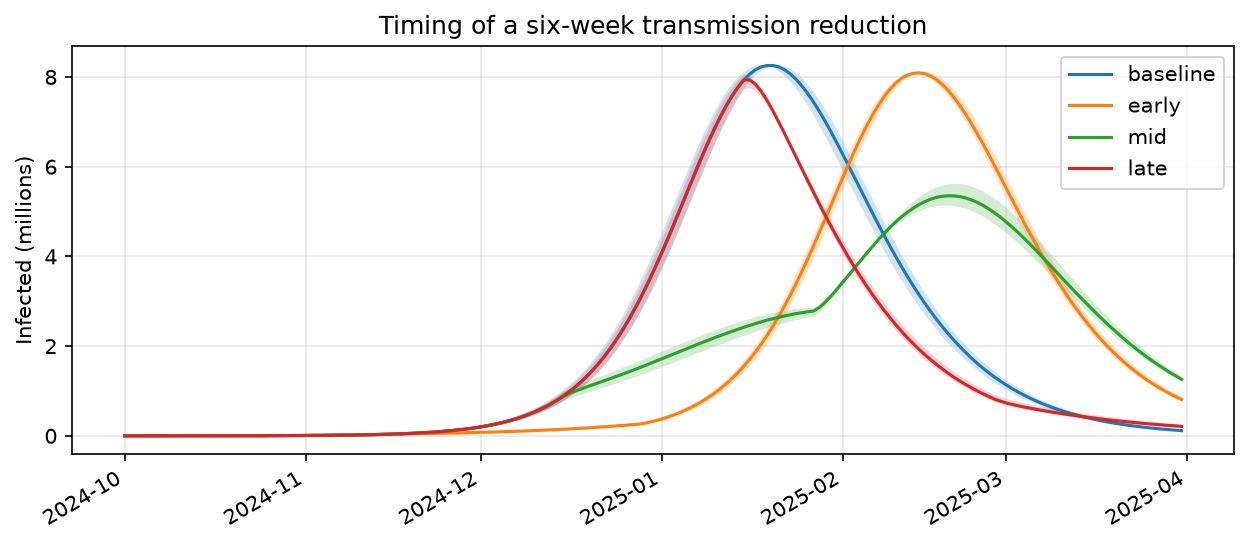

In [24]:
import matplotlib.pyplot as plt
from epydemix.io import add_figure_to_manifest, load_bundle_dataframe

fig, ax = plt.subplots(figsize=(10, 4), dpi=150)
for name in ["baseline", "early", "mid", "late"]:
    df = load_bundle_dataframe(f"{name}.epx", "compartments", columns=["sim_id", "date", "Infected_total"])
    runs = df.pivot(index="date", columns="sim_id", values="Infected_total")
    ax.plot(runs.index, runs.median(axis=1) / 1e6, label=name)
    ax.fill_between(runs.index, runs.quantile(0.05, axis=1) / 1e6, runs.quantile(0.95, axis=1) / 1e6, alpha=0.2)

ax.set_ylabel("Infected (millions)")
ax.set_title("Timing of a six-week transmission reduction")
ax.legend()
ax.grid(alpha=0.3)
fig.autofmt_xdate()

Figures can be stored inside a bundle and listed in its manifest, so they stay with the data they show:

In [25]:
fig.savefig("baseline.epx/figures/scenarios.png")
add_figure_to_manifest("baseline.epx", "scenarios.png", "Infected_total, four intervention timings", ["Infected_total"])

For the calibration, `epydemix inspect calibration.epx fit` returns the quantiles of the fitted trajectories together with the observed data. CLI commands can be called from Python like this:

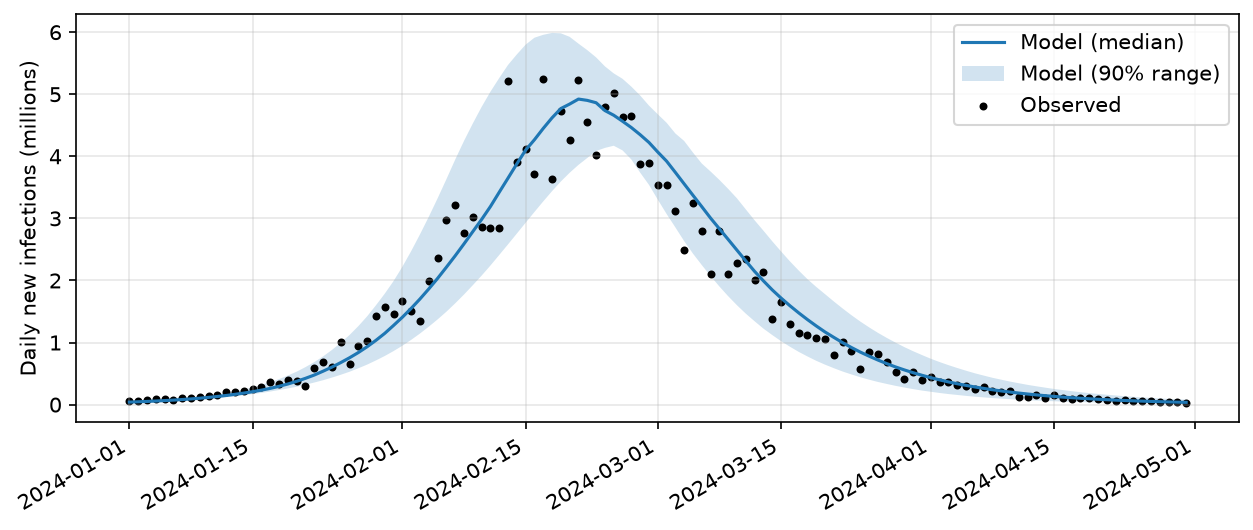

In [26]:
import json

fit = json.loads(subprocess.check_output(
    ["epydemix", "inspect", "calibration.epx", "fit", "-v", "Susceptible_to_Infected_total", "-q", "0.05,0.5,0.95"]
))
variable = "Susceptible_to_Infected_total"
quantiles = {q: np.array(values) / 1e6 for q, values in fit[variable].items()}
observed = np.array(fit["observed"][variable]) / 1e6
dates = pd.read_csv("incidence_data.csv", parse_dates=["date"])["date"]

fig, ax = plt.subplots(figsize=(10, 4), dpi=150)
ax.plot(dates, quantiles["0.5"], label="Model (median)")
ax.fill_between(dates, quantiles["0.05"], quantiles["0.95"], alpha=0.2, label="Model (90% range)")
ax.scatter(dates, observed, s=8, color="k", label="Observed")
ax.set_ylabel("Daily new infections (millions)")
ax.legend()
ax.grid(alpha=0.3)
fig.autofmt_xdate()

## 7. Driving epydemix with an agent

Everything above can be done by an LLM agent that can run shell commands, such as Claude Code, Codex, or Gemini CLI. The agent's reference is [`AGENT.md`](https://github.com/epistorm/epydemix/blob/main/AGENT.md) at the root of the repository: it documents every command, the full config format, the bundle layout, and pitfalls to avoid. [`AGENT_EXAMPLES.md`](https://github.com/epistorm/epydemix/blob/main/AGENT_EXAMPLES.md) adds plotting recipes and end-to-end examples.

To use it, install `epydemix[agent]` where the agent runs and point it to `AGENT.md`. For example:

> *Read AGENT.md, then use epydemix to simulate a COVID-19-like epidemic in Italy for the 2024-25 season with R0 = 2.5. Compare a six-week, 40% reduction in transmission starting in mid-November, mid-December, or mid-January, and tell me which timing minimizes the peak and which minimizes the attack rate. Save a figure.*

The agent then goes through the same steps as this tutorial: `models`, `schema`, and `defaults` to discover what's available, a baseline config and three overlays checked with `validate`, `run` for each, `compare` to answer the question, and a plot saved in a bundle. Because every step is a command that reads and writes files, each result can be checked afterwards: the configs, seeds, and provenance are all in the bundles.

## Summary

| Task | Command |
|------|---------|
| List models | `epydemix models` |
| Describe a model's parameters | `epydemix schema SEIR [--format describe]` |
| Disease presets | `epydemix defaults [covid19]` |
| Available populations | `epydemix populations` |
| Check a config | `epydemix validate config.yaml` |
| Run simulations | `epydemix run config.yaml -o results.epx` |
| Query results | `epydemix inspect results.epx peak/summary/quantiles/manifest` |
| Compare scenarios | `epydemix compare a.epx b.epx -b a` |
| Calibrate | `epydemix calibrate calibration.yaml -o calibration.epx` |
| Posterior and fit | `epydemix inspect calibration.epx posterior/fit` |
| Project | `epydemix project calibration.epx [-c overlay.yaml] -o projection.epx` |

For the complete reference, see [`AGENT.md`](https://github.com/epistorm/epydemix/blob/main/AGENT.md).